# 02 · Diagnóstico do score atual (baseline)

Precisamos entender o que estamos tentando superar, ou seja, o quão bem o score em produção ordena o risco, se ele é estável no tempo e onde falha. 

Os pontos fracos do modelo atual podem indicar onde e como o novo modelo pode gerar valor.

Além disso, como o score já vem de um modelo treinado anteriormente, podemos avaliá-lo na base inteira **sem risco de vazamento**

> Visando comparações futuras com o novo modelo, preservaremos os números de
cada partição no mesmo período de teste.

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

In [2]:
df = dados.carregar_base()
y, s = df["fraude"], df["score"]
df.shape

(150000, 21)

## 1. Decisão por trás de cada métrica *(pergunta 2)*

- **ROC AUC** → mede a capacidade de **ordenação** de fraudes pelo score do modelo (quanto maior o score, mais fraudes);
- **PR AUC (AP)** → mede a estabilidade da **precisão** a medida que o recall muda (foco na precisão, visto que a métrica anterior pode ser enganosa para datasets desbalanceados);
- **KS** → mede a **separação máxima** entre as distribuições; neste caso, o quanto o modelo separa fraude de transação legítima;
- **Recall @ FPR x%** → explicita a **taxa de fraudes** reais capturadas considerando um limite operacional de envio de falsos positivos até um percentual específico de **x%**;
- **Lucro (R$)** → resultado financeiro, considerando a política de corte (**métrica principal de decisão**).

In [3]:
print("Resumo das métricas:")

tabela = pd.concat(
    [metricas.resumo(y, s, df["monto"], nome="Base completa")] +
    [metricas.resumo(g["fraude"], g["score"], g["monto"], nome=p.capitalize())
     for p, g in df.groupby("particao", sort=False)], axis=1)
tabela

Resumo das métricas:


,Base completa,Treino,Validacao,Teste
ROC AUC,0.7263,0.7246,0.7295,0.7264
PR AUC (AP),0.1765,0.1519,0.2549,0.2269
KS,0.4315,0.4124,0.4491,0.4535
Recall @ FPR 1%,0.0854,0.0650,0.1341,0.1579
Recall @ FPR 5%,0.3026,0.2472,0.4012,0.4180
Recall @ FPR 10%,0.4759,0.4166,0.5248,0.5274
Recall R$ @ FPR 5%,0.2985,0.2406,0.4025,0.4410


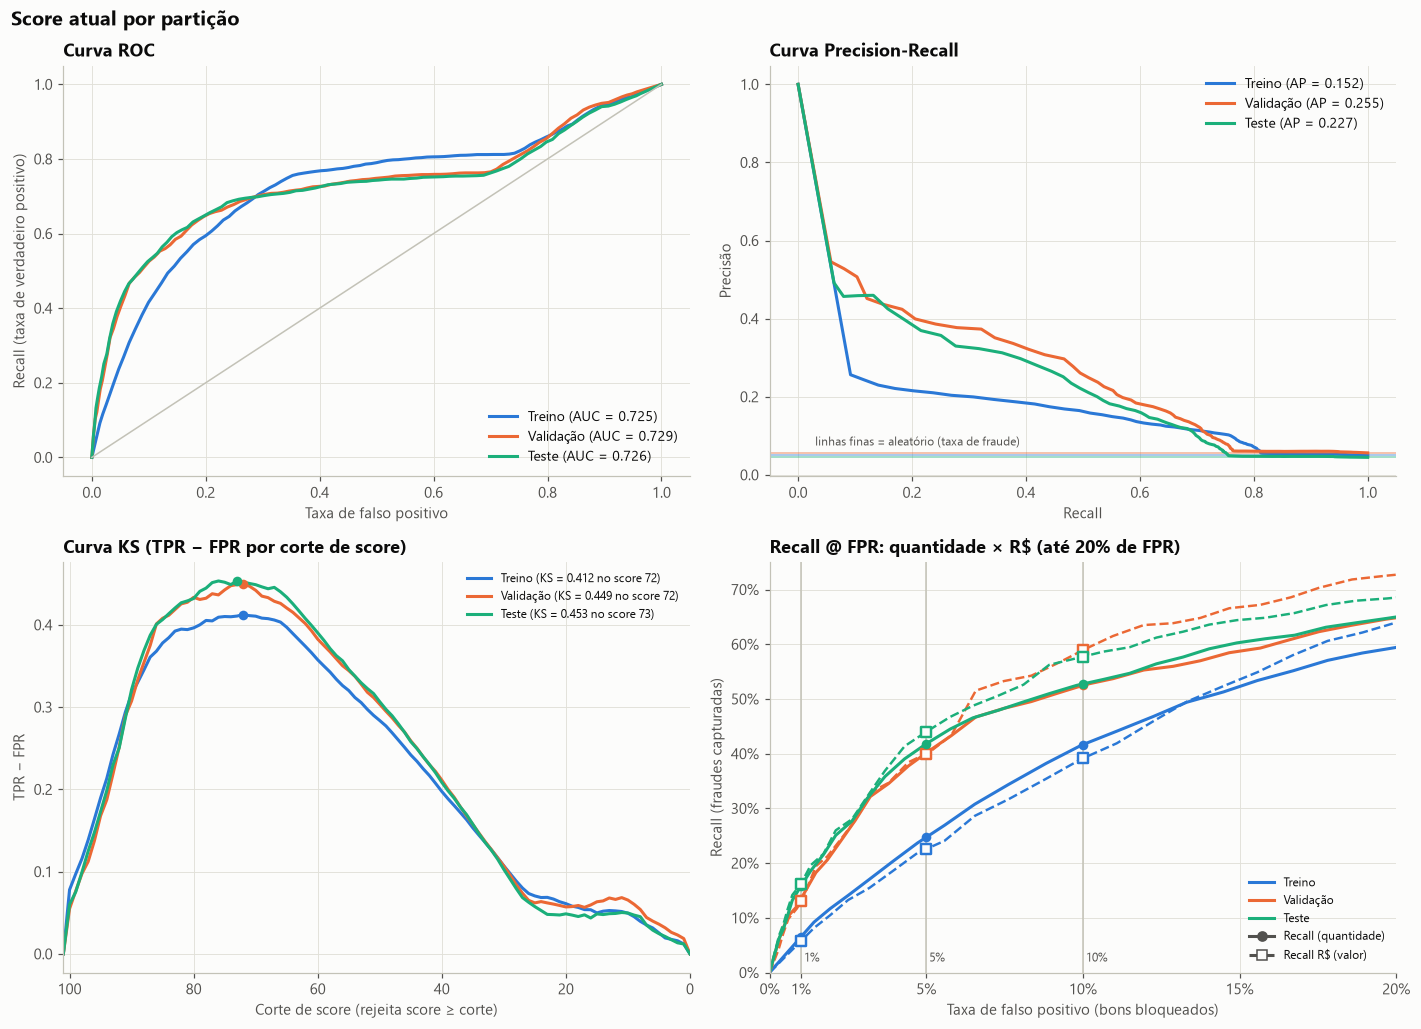

In [4]:
# Curvas do score atual por partição: ROC, Precision-Recall, KS e Recall @ FPR
from sklearn.metrics import roc_curve, precision_recall_curve

cores = {"treino": gr.AZUL, "validacao": gr.LARANJA, "teste": gr.VERDE_AGUA}
nomes = {"treino": "Treino", "validacao": "Validação", "teste": "Teste"}
fprs_alvo = [0.01, 0.05, 0.10]


def curva_recall_valor(y, score, valor):
    """FPR e recall em R$ (fração do valor fraudado capturado) para cada corte de score."""
    t = (pd.DataFrame({"score": score, "legit": 1 - y, "vfraude": valor * y})
           .groupby("score")[["legit", "vfraude"]].sum().sort_index(ascending=False).cumsum())
    fpr_v = np.r_[0, t["legit"] / t["legit"].iloc[-1]]
    rec_v = np.r_[0, t["vfraude"] / t["vfraude"].iloc[-1]]
    return fpr_v, rec_v


fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
ax_roc, ax_pr, ax_ks, ax_rec = axes.flat

for part, g in df.groupby("particao", sort=False):
    yp, sp, cor, nome = g["fraude"], g["score"], cores[part], nomes[part]
    fpr, tpr, cortes = roc_curve(yp, sp)
    cortes = np.minimum(cortes, 101)  # o 1º corte do sklearn é +inf

    # ROC
    ax_roc.plot(fpr, tpr, color=cor, label=f"{nome} (AUC = {roc_auc_score(yp, sp):.3f})")

    # Precision-Recall (+ linha fina do aleatório: precisão = taxa de fraude da partição)
    prec, rec, _ = precision_recall_curve(yp, sp)
    ax_pr.plot(rec, prec, color=cor, label=f"{nome} (AP = {average_precision_score(yp, sp):.3f})")
    ax_pr.axhline(yp.mean(), color=cor, lw=1, alpha=0.5)

    # KS: distância entre as distribuições acumuladas (TPR - FPR) em cada corte de score
    dist = tpr - fpr
    i = np.argmax(dist)
    ax_ks.plot(cortes, dist, color=cor, label=f"{nome} (KS = {dist[i]:.3f} no score {cortes[i]:.0f})")
    ax_ks.scatter(cortes[i], dist[i], color=cor, s=40, zorder=3)

    # Recall @ FPR: zoom da ROC na região de baixo bloqueio de clientes bons
    # linha contínua = recall em quantidade | tracejada = recall em R$ (valor fraudado capturado)
    ax_rec.plot(fpr, tpr, color=cor)
    ax_rec.scatter(fprs_alvo, [metricas.recall_em_fpr(yp, sp, f) for f in fprs_alvo], color=cor, s=40, zorder=3)
    fpr_v, rec_v = curva_recall_valor(yp, sp, g["monto"])
    ax_rec.plot(fpr_v, rec_v, color=cor, ls="--", lw=1.6)
    ax_rec.scatter(fprs_alvo, [np.interp(f, fpr_v, rec_v) for f in fprs_alvo], marker="s", s=40,
                   facecolors=gr.SUPERFICIE, edgecolors=cor, linewidths=1.6, zorder=3)

ax_roc.plot([0, 1], [0, 1], color=gr.EIXO, lw=1)
ax_roc.set(title="Curva ROC", xlabel="Taxa de falso positivo", ylabel="Recall (taxa de verdadeiro positivo)")
ax_roc.legend(loc="lower right")

ax_pr.set(title="Curva Precision-Recall", xlabel="Recall", ylabel="Precisão")
ax_pr.text(0.03, 0.075, "linhas finas = aleatório (taxa de fraude)", ha="left", fontsize=8, color=gr.TINTA_2)
ax_pr.legend(loc="upper right")

ax_ks.set(title="Curva KS (TPR − FPR por corte de score)", xlabel="Corte de score (rejeita score ≥ corte)",
          ylabel="TPR − FPR", xlim=(0, 101))
ax_ks.invert_xaxis()
ax_ks.legend(loc="upper right", fontsize=8)

for f in fprs_alvo:
    ax_rec.axvline(f, color=gr.EIXO, lw=1)
    ax_rec.text(f, 0.02, f" {f:.0%}", fontsize=8, color=gr.TINTA_2)
ax_rec.set(title="Recall @ FPR: quantidade × R$ (até 20% de FPR)", xlabel="Taxa de falso positivo (bons bloqueados)",
           ylabel="Recall (fraudes capturadas)", xlim=(0, 0.2), ylim=(0, 0.75))
ax_rec.set_xticks([0, 0.01, 0.05, 0.10, 0.15, 0.20])
gr.formatar_pct(ax_rec, "x"); gr.formatar_pct(ax_rec)
from matplotlib.lines import Line2D
leg_cor = [Line2D([], [], color=cores[p], label=nomes[p]) for p in cores]
leg_tipo = [Line2D([], [], color=gr.TINTA_2, marker="o", label="Recall (quantidade)"),
            Line2D([], [], color=gr.TINTA_2, ls="--", marker="s", markerfacecolor=gr.SUPERFICIE, label="Recall R$ (valor)")]
ax_rec.legend(handles=leg_cor + leg_tipo, loc="lower right", fontsize=8)

fig.suptitle("Score atual por partição", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Análise:**

- **ROC AUC** moderado e consistente → boa capacidade de distinguir e ordenar pares de fraude e transações legítimas, mas ainda deve ser possível melhorar;

- **PR AUC / AP** baixo e instável, maior no teste → 3,5x maior que o acaso, mas instável entre populações, o que indica deterioração da precisão à medida que o recall cresce;
- **KS** moderado e consistente → separação relevante entre as distribuições dos scores (FPR e TPR);
- **Recall @ FPR (1, 5 e 10%)** de caráter logístico → a medida que aumentamos a tolerância a falsos positivos de 1 a 5%, passa a identificar ~40% das fraudes, e, de 5 a 10%, estabiliza em ~50% das fraudes. O maior ganho vem no inicio da curva;
- **Recall R$ @ FPR 5%** consistente com o Recall @ FPR 5% → não existe forte evidencia que o modelo é melhor em capturar fraudes de alto valor.

> **O modelo parece discriminar melhor as fraudes no topo do ranking durante o período de teste, apesar de haver menos fraudes proporcionalmente.**


> **Conclusão**: Há espaço para melhorar, principalmente na captura de fraudes sob restrição de falsos positivos e na ordenação das classificações.

## 2. Distribuição do score *(pergunta 2)*

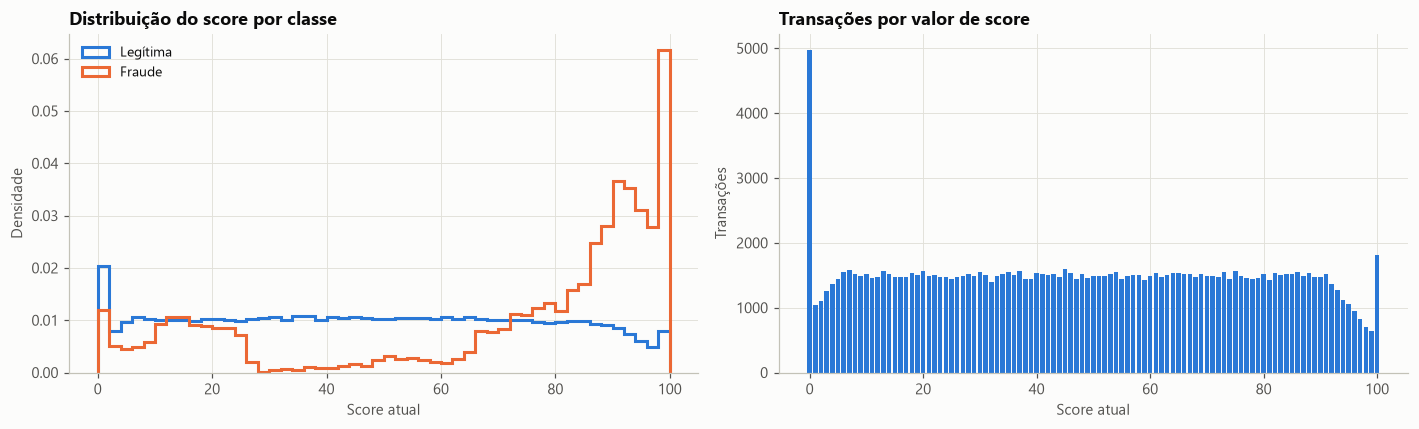

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.arange(0, 102, 2)
for alvo in [0, 1]:
    axes[0].hist(s[y == alvo], bins=bins, density=True, histtype="step", lw=2,
                 color=gr.COR_ALVO[alvo], label=gr.ROTULO_ALVO[alvo])
axes[0].set(title="Distribuição do score por classe", xlabel="Score atual", ylabel="Densidade")
axes[0].legend()

contagem = s.value_counts().sort_index()
axes[1].bar(contagem.index, contagem.values, color=gr.AZUL, width=0.8)
axes[1].set(title="Transações por valor de score", xlabel="Score atual", ylabel="Transações")
plt.tight_layout()

Cada valor de score concentra cerca de **1%** da base (percentil de risco)

A distribuição das fraudes é bimodal. Há o pico esperado em scores altos, mas também uma massa relevante de fraudes em scores baixos (0–25). **Talvez oportunidade para o novo modelo?**

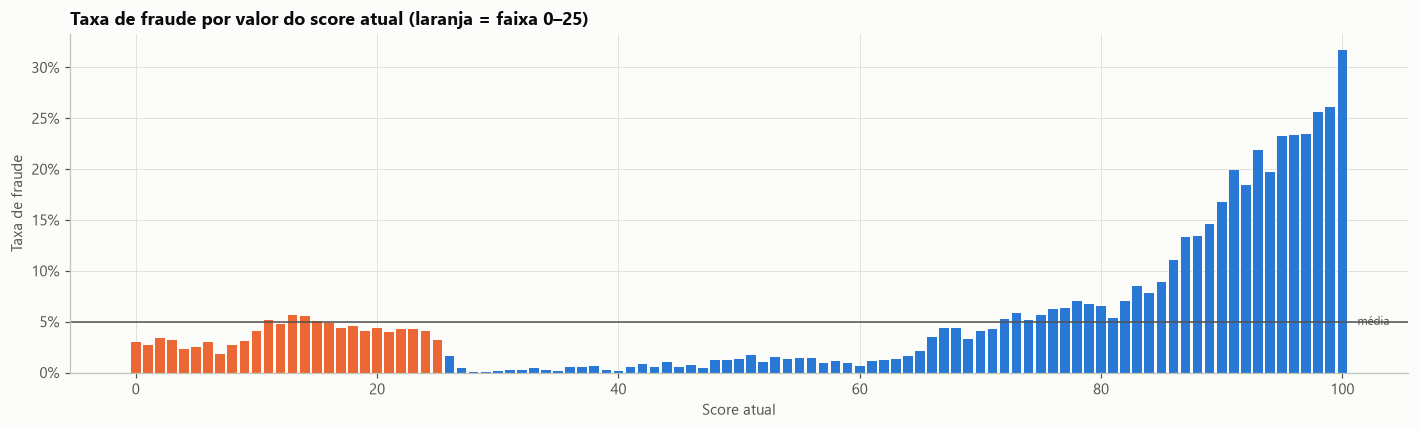

In [6]:
taxa_por_score = df.groupby("score")["fraude"].mean()

fig, ax = plt.subplots(figsize=(13, 4))
cores = np.where(taxa_por_score.index <= 25, gr.LARANJA, gr.AZUL)
ax.bar(taxa_por_score.index, taxa_por_score.values, color=cores, width=0.8)
ax.axhline(y.mean(), color=gr.TINTA_2, lw=1)
ax.text(101, y.mean(), " média", va="center", fontsize=8, color=gr.TINTA_2)
ax.set(title="Taxa de fraude por valor do score atual (laranja = faixa 0–25)",
       xlabel="Score atual", ylabel="Taxa de fraude")
gr.formatar_pct(ax)
plt.tight_layout()

In [7]:
print("Resumo das métricas por faixa de score:")

faixa = pd.cut(s, [-1, 25, 29, 60, 80, 100], labels=["0–25", "26–29", "30–60", "61–80", "81–100"])
zona = df.groupby(faixa, observed=True).agg(transacoes=("fraude", "size"), fraudes=("fraude", "sum"),
                                            taxa_fraude=("fraude", "mean"))
zona["%_transacoes"] = zona["transacoes"] / len(df)
zona["%_das_fraudes"] = zona["fraudes"] / y.sum()
# ROC AUC *dentro* de cada faixa: o score ainda ordena o risco ali dentro?
zona["auc_dentro_da_faixa"] = df.groupby(faixa, observed=True).apply(
    lambda g: roc_auc_score(g["fraude"], g["score"]) if g["fraude"].nunique() > 1 else np.nan)
zona

Resumo das métricas por faixa de score:


,transacoes,fraudes,taxa_fraude,%_transacoes,%_das_fraudes,auc_dentro_da_faixa
score,,,,,,
0–25,41268,1572,0.0381,0.2751,0.2096,0.5445
26–29,5971,33,0.0055,0.0398,0.0044,0.2128
30–60,46460,363,0.0078,0.3097,0.0484,0.6292
61–80,29987,1287,0.0429,0.1999,0.1716,0.6295
81–100,26314,4245,0.1613,0.1754,0.5660,0.6538


Na faixa **0–25**, que reúne **~28%** das transações, a taxa de fraude é ~3,8%, próxima da média de 5% da base. Dentro dela o score praticamente não ordena o risco (AUC ≈ 0,54, próximo do aleatório (0,5)). 

Ou seja, o modelo atual parece atribuir "baixo risco" sem distinguir fraude de transação legítima. Essa faixa concentra **~21%** de todas as fraudes, e como a maioria das políticas de corte aprovam scores baixos, essas fraudes passam sempre.

Na faixa logo acima, de **26–29**, a taxa despenca para **~0,5%**, e a partir daí o score volta a ser crescente
  **(quanto maior o score, maior o risco)**.

> **Oportunidade**: identificar essas fraudes no novo modelo!

## 3. Estabilidade temporal

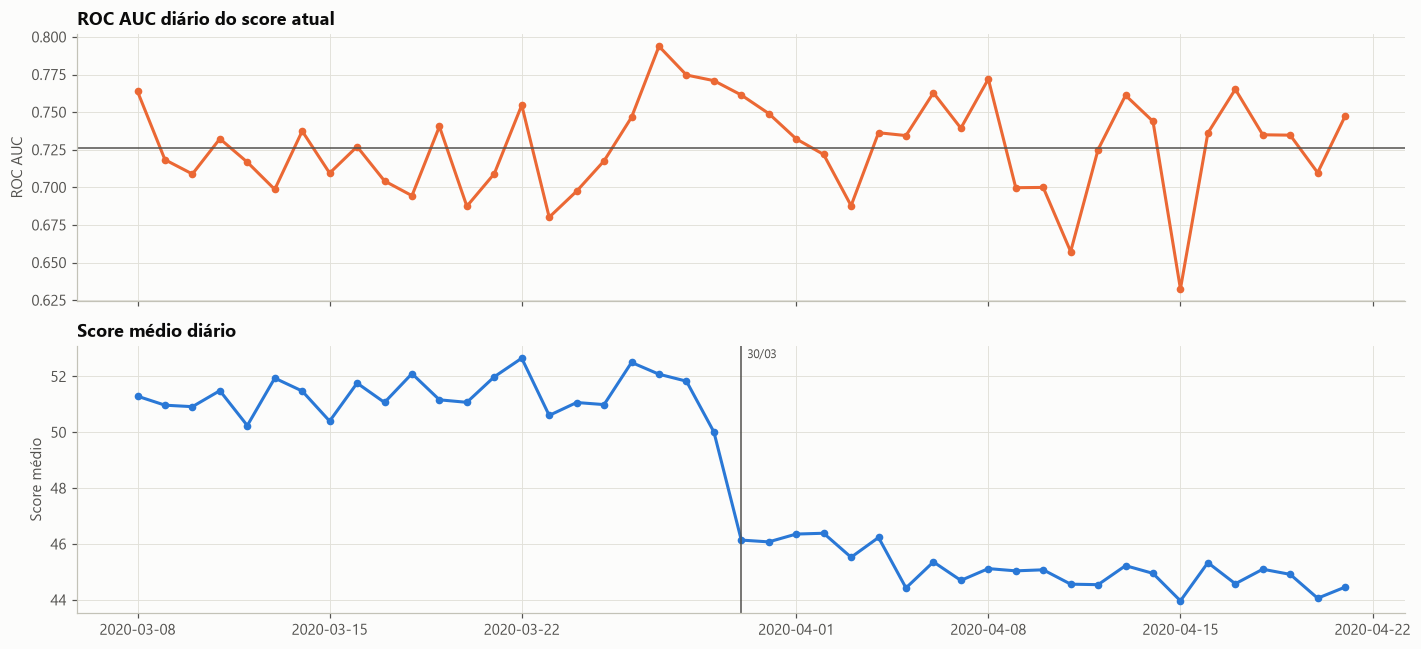

In [8]:
dia = df["fecha"].dt.normalize()
estab = df.groupby(dia).apply(lambda g: pd.Series({
    "roc_auc": roc_auc_score(g["fraude"], g["score"]),
    "score_medio": g["score"].mean(),
}))

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(estab.index, estab["roc_auc"], color=gr.LARANJA, marker="o", ms=4)
axes[0].axhline(roc_auc_score(y, s), color=gr.TINTA_2, lw=1)
axes[0].set(title="ROC AUC diário do score atual", ylabel="ROC AUC")
axes[1].plot(estab.index, estab["score_medio"], color=gr.AZUL, marker="o", ms=4)
axes[1].axvline(pd.Timestamp("2020-03-30"), color=gr.TINTA_2, lw=1)
axes[1].text(pd.Timestamp("2020-03-30"), estab["score_medio"].max(), "  30/03", fontsize=8, color=gr.TINTA_2)
axes[1].set(title="Score médio diário", ylabel="Score médio")
plt.tight_layout()

In [9]:
# PSI semanal do score contra a primeira semana (referência)
semana = df["fecha"].dt.to_period("W-SAT")
ref = df.loc[semana == semana.min(), "score"]
psi_semanal = pd.Series({str(w.start_time.date()): metricas.psi(ref, g["score"])
                         for w, g in df.groupby(semana)}, name="PSI vs 1ª semana")
psi_semanal.to_frame().T

,2020-03-08,2020-03-15,2020-03-22,2020-03-29,2020-04-05,2020-04-12,2020-04-19
PSI vs 1ª semana,0.0000,0.0007,0.0013,0.0474,0.0746,0.0854,0.0850


- O **ROC AUC** diário oscila entre **~0,63** e **~0,79**
  - O pior valor é no dia **15/04**, o dia atípico identificado anteriormente.
- O **score médio** cai de **~51** para **~45** a partir de **30/03** e se mantém nesse novo patamar. 
  - Esse degrau sugere uma possível mudança no modelo ou na população (retreino, nova versão, etc.). 
  - O PSI fica baixo (< 0,1, considerado estável), então a mudança é sutil.

## 4. Baseline a ser batido (período de teste) *(pergunta 2)*

In [10]:
teste = df[df["particao"] == "teste"]
baseline = metricas.resumo(teste["fraude"], teste["score"], teste["monto"], nome="Score atual — teste OOT")
baseline.to_frame()

,Score atual — teste OOT
ROC AUC,0.7264
PR AUC (AP),0.2269
KS,0.4535
Recall @ FPR 1%,0.1579
Recall @ FPR 5%,0.4180
Recall @ FPR 10%,0.5274
Recall R$ @ FPR 5%,0.4410


## 5. Conclusões

1. O desempenho do modelo anterior é **moderado**

   - Na base completa, **ROC AUC ≈ 0,73**, **PR AUC ≈ 0,18** e **KS ≈ 0,43** 
   - No conjunto de teste, **ROC AUC ≈ 0,73**, **PR AUC ≈ 0,23** e **KS ≈ 0,45**.
2. O score é um **percentil**, não uma **probabilidade** 
   - Para decisões por custo esperado precisaremos escolher o corte empiricamente.
3. Existe oportunidade na faixa de scoragem de **0–25**: 
   - **~21%** das fraudes recebem score baixo e passam por qualquer política de corte. Dentro dessa faixa o score é equivalente a um sorteio, mas **provavelmente há sinal nos dados** (ex.: `o`).
4. Instabilidade 
   - **AUC** diário variando bastante e um degrau no score médio em 30/03, o que mostra que o modelo em produção precisa de monitoramento.